<a href="https://colab.research.google.com/github/farrelandika/PCVK_Genap_2021/blob/main/Modul9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 – Morfologi Citra (Tugas Praktikum D)
**Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi**

Notebook ini berisi pengerjaan **D. TUGAS PRAKTIKUM** (Soal 3 s.d. 17) menggunakan path citra yang ditentukan:
- Citra Plat: `/content/drive/MyDrive/PCVK/Plat.png`
- Citra Lily: `/content/drive/MyDrive/PCVK/360_F_1516498084_a8Ggba1buDEEUA2mZiXw3IjjC3v79a86.jpg`


## 1. Import Library & Mount Google Drive

In [19]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Bukan Colab / drive tidak ter-mount, lanjut tanpa Drive.', e)

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, morphology, color, img_as_float

# Path khusus sesuai instruksi
PLAT_PATH = '/content/drive/MyDrive/PCVK/Plat.png'
LILY_PATH = '/content/drive/MyDrive/PCVK/360_F_1516498084_a8Ggba1buDEEUA2mZiXw3IjjC3v79a86.jpg'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Dilasi SE cross 3×3 tanpa library morphology

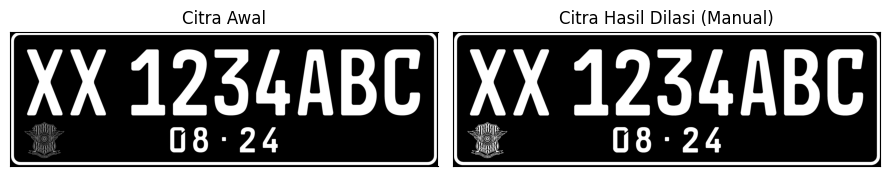

In [2]:
img_d = load_img('plat')
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
imgD = dilasi_citra(thresh, se_cross(3))
tampil([img_d, imgD], ['Citra Awal', 'Citra Hasil Dilasi (Manual)'])

## Dilasi SE cross 3×3 dengan library OpenCV

Kernel Cross 3x3:
 [[0 1 0]
 [1 1 1]
 [0 1 0]]


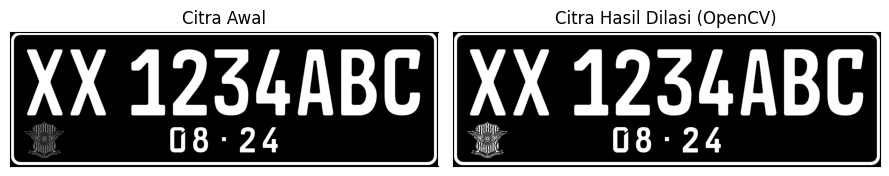

In [3]:
img = load_img('plat', gray=False)
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
ret, thresh = cv2.threshold(gray_img, 127, 255, cv2.THRESH_BINARY)
kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print("Kernel Cross 3x3:\n", kernel)
tampil([img, dilasi], ['Citra Awal', 'Citra Hasil Dilasi (OpenCV)'])

## Erosi SE square 5×5 tanpa library morphology

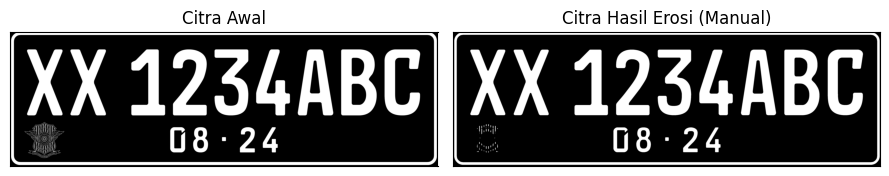

In [4]:
img_e = load_img('plat')
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)
imgE = erosi_citra(thresh1, se_square(5))
tampil([img_e, imgE], ['Citra Awal', 'Citra Hasil Erosi (Manual)'])

## Erosi SE square 5×5 dengan library OpenCV

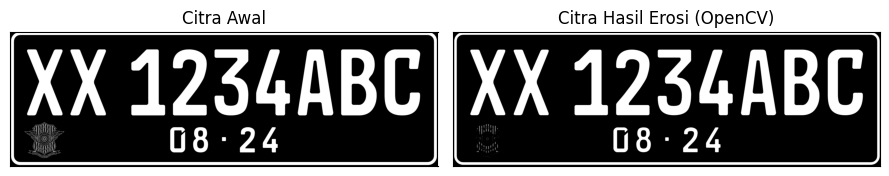

In [5]:
img = load_img('plat', gray=False)
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)
tampil([img, erosion], ['Citra Awal', 'Citra Hasil Erosi (OpenCV)'])

## Opening SE square 3×3 tanpa dan dengan library

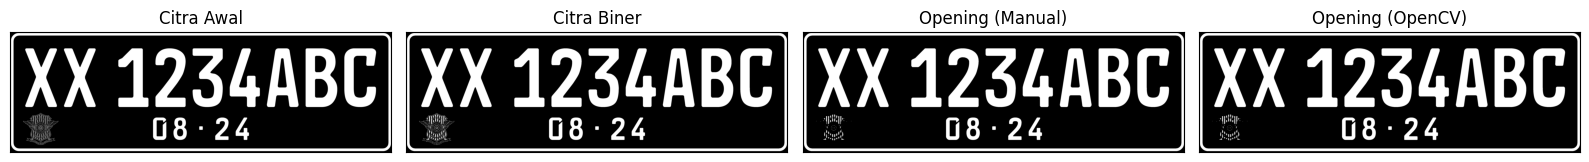

In [6]:
img_o = load_img('plat')
reto, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)

imgO = opening_citra(thresho, se_square(3))

kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresho, cv2.MORPH_OPEN, kernel)

tampil([img_o, thresho, imgO, openn],
       ['Citra Awal', 'Citra Biner', 'Opening (Manual)', 'Opening (OpenCV)'], w=4)

## Closing SE square 3×3 tanpa dan dengan library

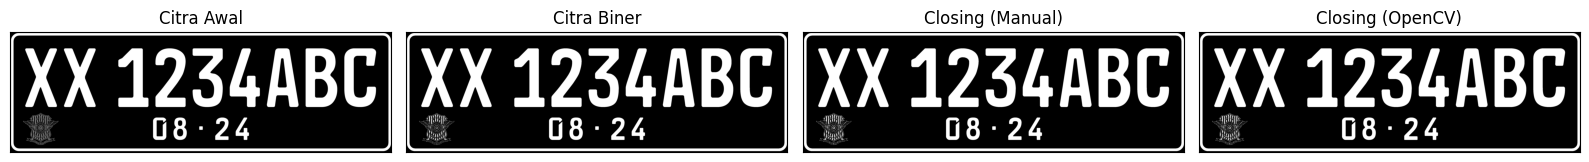

In [7]:
img_c = load_img('plat')
retc, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)

imgC = closing_citra(threshc, se_square(3))

kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(threshc, cv2.MORPH_CLOSE, kernel)

tampil([img_c, threshc, imgC, closs],
       ['Citra Awal', 'Citra Biner', 'Closing (Manual)', 'Closing (OpenCV)'], w=4)

## Dilasi SE Cross 3×3 dan 5×5

SED = Cross 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


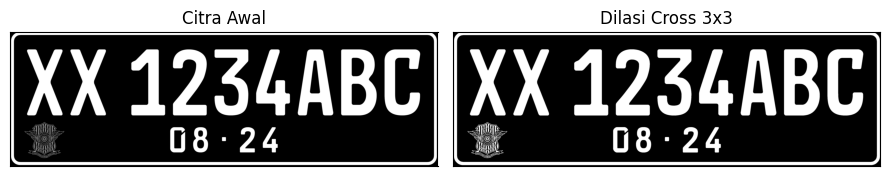

SED = Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


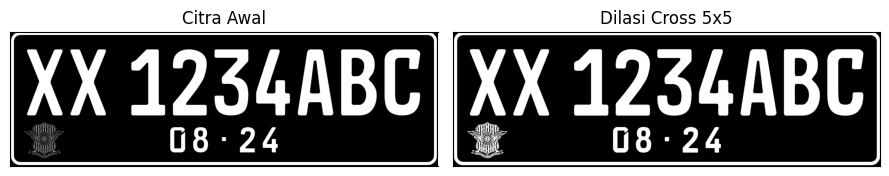

In [8]:
img_d = load_img('plat')
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
for w in (3, 5):
    print(f'SED = Cross {w}x{w}:')
    print(se_cross(w))
    tampil([img_d, dilasi_citra(thresh, se_cross(w))], ['Citra Awal', f'Dilasi Cross {w}x{w}'])

## Dilasi SE Circular 3×3 dan 5×5

SED = Circle 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


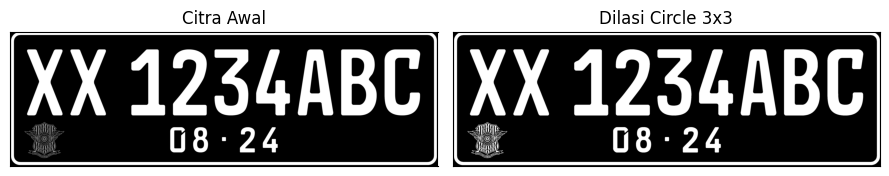

SED = Circle 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


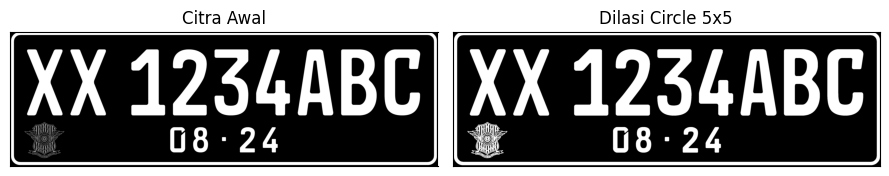

In [9]:
img_d = load_img('plat')
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
for w in (3, 5):
    print(f'SED = Circle {w}x{w}:')
    print(se_circle(w))
    tampil([img_d, dilasi_citra(thresh, se_circle(w))], ['Citra Awal', f'Dilasi Circle {w}x{w}'])

## Erosi SE Rectangle 3×5 dan 5×7

SE = Rectangle 3x5:


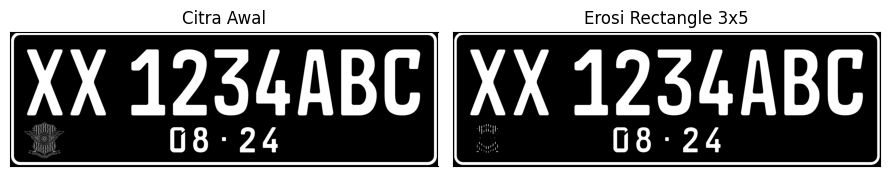

SE = Rectangle 5x7:


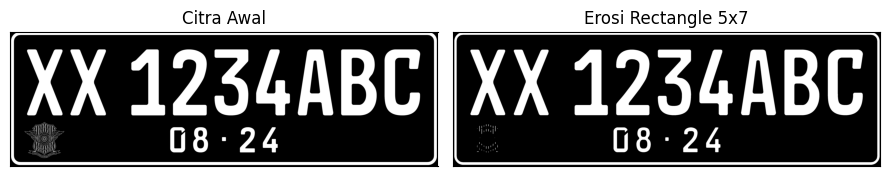

In [10]:
img_e = load_img('plat')
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)
for (r, c) in [(3, 5), (5, 7)]:
    print(f'SE = Rectangle {r}x{c}:')
    tampil([img_e, erosi_citra(thresh1, se_rect(r, c))], ['Citra Awal', f'Erosi Rectangle {r}x{c}'])

## Erosi SE Line Vertikal 3 dan 5

SE = Line Vertikal 3:


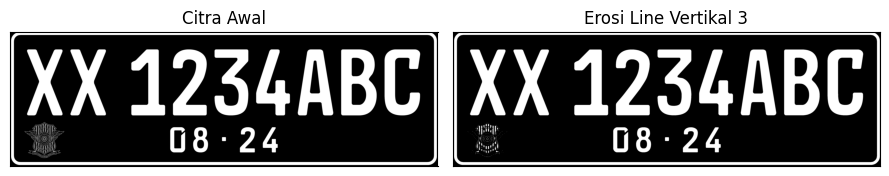

SE = Line Vertikal 5:


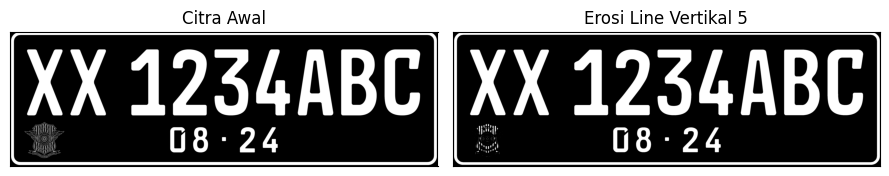

In [18]:
img_j = load_img('/content/drive/MyDrive/PCVK/Plat.png')
ret1, thresh_j = cv2.threshold(img_j, 127, 255, cv2.THRESH_BINARY)
for k in (3, 5):
    print(f'SE = Line Vertikal {k}:')
    tampil([img_j, erosi_citra(thresh_j, se_line_v(k))], ['Citra Awal', f'Erosi Line Vertikal {k}'])

## Top-Hat

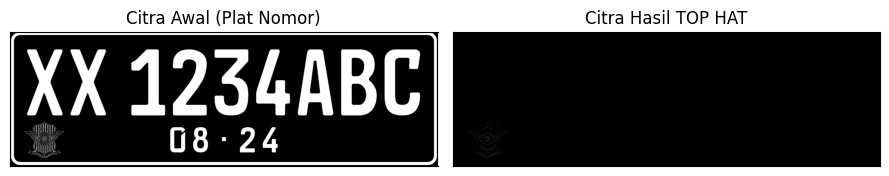

In [12]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
for key, name in [('plat', 'Plat Nomor')]:
    img = load_img(key)
    tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
    tampil([img, tophat_img], [f'Citra Awal ({name})', 'Citra Hasil TOP HAT'])

## Black-Hat

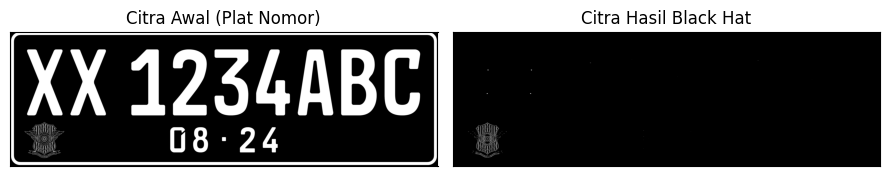

In [13]:
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
for key, name in [('plat', 'Plat Nomor')]:
    img = load_img(key)
    blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, kernel)
    tampil([img, blackhat], [f'Citra Awal ({name})', 'Citra Hasil Black Hat'])

 Skeleton

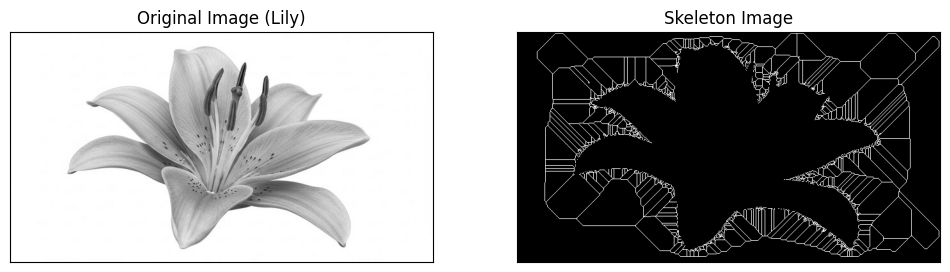

In [14]:
from skimage import filters
from skimage.morphology import skeletonize

img = load_img('lily')
binary = img > filters.threshold_triangle(img)
binary_cp = binary.astype(np.uint8)
skeleton = skeletonize(binary_cp)

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original Image (Lily)'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray'), plt.title('Skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig('binary_and_bin_skeleton.png')
plt.show()

 Skeleton Inverse

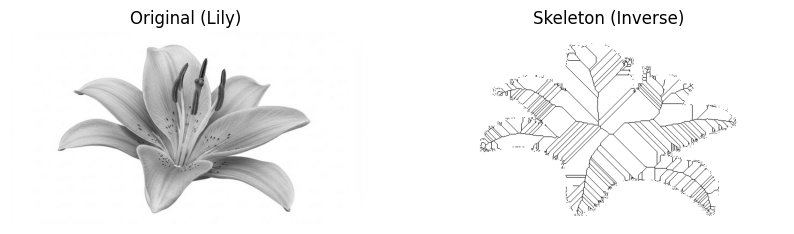

In [15]:
img = load_img('lily')
binary = img < filters.threshold_triangle(img)
skeleton = skeletonize(binary)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original (Lily)')
ax[0].set_axis_off()
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()
plt.show()



```
# This is formatted as code
```

## Thinning & Thickening
Implementasi thinning dan thickening berbasis *hit-or-miss* dengan 8 Structuring Elements (B1–B8):
- Thinning: $A \otimes B = A - (A \circledast B)$
- Thickening: $A \odot B = A \cup (A \circledast B)$

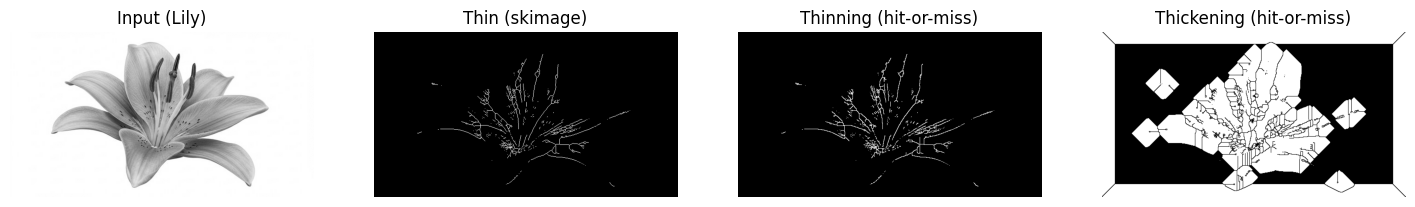

In [16]:
def daftar_SE_hitmiss():
    ring = [(0,0),(0,1),(0,2),(1,2),(2,2),(2,1),(2,0),(1,0)]
    nilai = [-1,-1,-1,0,1,1,1,0]
    hasil = []
    for k in range(8):
        se = np.zeros((3, 3), np.int8)
        se[1, 1] = 1
        for (pos, v) in zip(ring, nilai[-k:] + nilai[:-k] if k else nilai):
            se[pos] = v
        hasil.append(se)
    return hasil

def thinning_hitmiss(A, max_iter=100):
    A = (A > 0).astype(np.uint8)
    for _ in range(max_iter):
        sebelum = A.copy()
        for se in daftar_SE_hitmiss():
            hm = cv2.morphologyEx(A, cv2.MORPH_HITMISS, se)
            A = A & (1 - hm)
        if np.array_equal(A, sebelum):
            break
    return A

def thickening_hitmiss(A, max_iter=30):
    A = (A > 0).astype(np.uint8)
    Ap = np.pad(A, 1, constant_values=0)
    komp = 1 - Ap
    komp = np.pad(komp, 1, constant_values=1)
    hasil = 1 - thinning_hitmiss(komp, max_iter)
    return hasil[2:-2, 2:-2]

img_lily = load_img('lily', gray=False)
image = img_as_float(color.rgb2gray(cv2.cvtColor(img_lily, cv2.COLOR_BGR2RGB)))
image_binary = image < 0.5

out_thin = morphology.thin(image_binary)
out_thin_hm = thinning_hitmiss(image_binary)
out_thick = thickening_hitmiss(image_binary)

f, ax = plt.subplots(1, 4, figsize=(18, 4.5))
for a, im, t in zip(ax, [image, out_thin, out_thin_hm, out_thick],
                    ['Input (Lily)', 'Thin (skimage)', 'Thinning (hit-or-miss)', 'Thickening (hit-or-miss)']):
    a.imshow(im, cmap='gray')
    a.set_title(t)
    a.set_axis_off()
plt.savefig('char_out.png')
plt.show()